### Metahuristics Assigment


#### Part One: Hill climbing algorithm implementation

In [33]:
import numpy as np
import time 
import matplotlib.pyplot as plt
import mplcursors
import seaborn as sns
import mplcursors
import ipympl
import sys
sys.path.append("../helper")
from workload_data_loader import load_workload_instance as ld
from itertools import combinations
print(ipympl.__version__)

0.10.0


Helper functions for one instance
- fitness(x):evaluation of total utility
- is_feasible(x):evaluation of constraints passed over or not

In [34]:
def fitness(x:np.ndarray,p:np.ndarray):
   return p @ x

def is_feasible(x:np.ndarray,r:np.ndarray,b:np.ndarray):
    return np.all(r @ x <= b)

Helper: Generation of initial state using seed so its reproducible

In [35]:
# rng = np.random.default_rng(44)
def generate_initial_state(seed,size:int,demands,capacities):
    # Will repeat until initial feasible state is acquired although the deterministic first value for seed 42 is feasible anywhay
    while True:
        x = seed.integers(0,2,size=size)
        if(is_feasible(x,demands,capacities)): 
            # print(f"fitness :{fitness(x,utilities)}")
            return x

Neighbourhood / Manipulation Functions 

In [36]:
# Neighbourhood manipulation function: 
# single bit manipulation
def generate_neighbour_single_bit(x:np.ndarray):
    neighbours = []
    for i in range(len(x)):
        neighbour = x.copy()
        neighbour[i] = 1-x[i]
        neighbours.append(neighbour)
    return np.array(neighbours)

# multi bit manipulation
# The logic is using xor bit manipulation with a mask containing 1 where you want to change values
# and 0 where you dont
# the combination function allows us to create all the combinations possible for that exact length and bit manipulation number
# 28Ck(bit manipulation number)

def generate_neighbours_multi_bit(x:np.ndarray,k:int):
    n = len(x)
    # Creating all the combinations for the length and bit manipulation number
    positions = list(combinations(range(n),k))
    # Create a mask for it 
    masks = np.zeros((len(positions),n),dtype=int)
    for i,pos in enumerate(positions):
        masks[i, list(pos)] = 1
        
    return np.bitwise_xor(x,masks)

# This pairing will create all the possible pairings for the selected 
# generator function which is also recursive which will make all the pairing we need for the swaps in 
# it takes in all the pisitions selected from the combination the tuple
# Then produces each distict pairing for it at every yield
# ex (0,1,2,3) positions chosen
def pairings(items):
    # items (0,1,2,3), (2,3)
    if not items: # false,false,true
        yield () # This is the base boolean expression for the recursion basically you will see it returns an empty tuple which joins at the end
        return 
    first = items[0] # 0,2
    for i in range(1,len(items)): #1->4 , #1,2
        second = items[i] #1,3
        remaining = items[1:i] + items[i+1:] # () + (3,4) = (3,4) , () + () = () 
        for rest in pairings(remaining): # Recursive call rest =()
            yield((first,second),) + rest # ((2,3),) + () = (2,3) , ((1,2),) + (2,3) = ((1,2),(2,3)) This is yielded in the for loop in neigbourhood function  

    
    

def generate_neighbours_multi_swap(x:np.ndarray,k:int):
    # We will only go uptil k=2 becuase k=3 by using this formula 28!/(n-2(2))!2^k*k! = 5651100 variations considered
    # which if repeated say 48 times means that it is evaluating same as brute force with maybe even less accuracy
    
    n = len(x)
    neighbours = []
    # 2 multipled because first part is nC2k why? for say one swap you choose two bits out of whole collection of bits
    # so say for two-swap you would choose 4 so it becomes nC2k and this gives us all the combination of selected bits
    # These bits will be seperated into pairs of two which will be use to commence all the swaps
    for selected in combinations(range(n),2*k):
        for pairs in pairings(selected): 
            #pairs 1((0,1),(2,3)), pairs2 ((0,2),(1,3)), pairs3 ((0,3),(1,2))
            # Here basically now just use the position of the swaps to implement the swaps
            neighbour = x.copy()
            for i,j in pairs: #(0,1) , (2,3)
                # Thus neighbour i and j switch the bits
                neighbour[i],neighbour[j] = neighbour[j],neighbour[i]
            neighbours.append(neighbour)
    return np.unique(np.array(neighbours),axis=0)


Constraint Handling Functions

In [ ]:
# These will be modularly added same as muatation 

# This will just filter out the values generated in the neighbourhood solution to only contain feasible values
def constraint_handling_rejection(neighbours,utilities,demands,capacities): # Utilities here cause the other constraint handler needs it and function call is not abstracterd
    return np.asarray([neighbour for neighbour in neighbours if is_feasible(neighbour,demands,capacities)])
    

# This will work like this it will calculate the ratios between profits/demands 
# Then remove that exist in the state with the lowest ratio for profit/demand
# Since there are two profit/demands. The way it does is this is check which one is being exceeded
# And then removes the lowest ratio bit for that 
# IF both are over than another ratio caluclated of which one is actually more exceeded_capacity1/demands or exceeded_capacity2/demands
def constraint_handling_greedy_repair(neighbours,utilities,demands,capacities):
    repaired_neighbours = []
    for neighbour in neighbours:
        repaired = neighbour.copy()
        # Infinite loop of removing the bits until feasible
        while not is_feasible(repaired,demands,capacities):
            # Gives out the array which has two values one for the first constraint and one for the next
            loads = demands @ repaired
            # Basically how much is exceeded from capacity
            violations = loads - capacities
            # Tells us  which constraints passed over
            # violated_constraints = violations > 0 # this gives us True,True or True,False or False,True
            
            # Now we need to calculate the relative violations 
            # This combines the above step so if the violation occurs its ratio is calculated if not 0 is placed there
            relative_violations = np.where(violations>0,violations/capacities,0)
            target = np.argmax(relative_violations) # Gives us the index of the higgest violation
            
            # Gives us the indices of the selected points in the current state
            selected_states_indices = np.flatnonzero(repaired)
            # any zero demands item is removed
            candidates = selected_states_indices[demands[target,selected_states_indices] > 0]
            
            # now the ratios for this utility/demand for each item
            ratios = utilities[candidates] / demands[target,candidates]
            # now get the index of the worst item by getting the worst ratio 
            worst_item_index =  candidates
            
            normalised_demands = demands[violated_constraints]
            
            

Neigbourhood selction function

In [38]:
# Choosing a better neighbour
def best_neighbour(x:np.ndarray,p:np.ndarray,r:np.ndarray,b,m:callable,constraint_handler,*args):
    neighbours = constraint_handler(m(x,*args),p,r,b)
    best_state = None
    best_fitness = fitness(x,p) 
    evaluations = 0
    for neighbour in neighbours:
        # if is_feasible(neighbour,r,b): This is now modular
            neighbour_fitness = fitness(neighbour,p)
            evaluations += 1
            if neighbour_fitness > best_fitness:
                best_state = neighbour
                best_fitness = neighbour_fitness
                # print(best_fitness)
    return best_state, best_fitness, evaluations

Hill climbing algorithm

In [39]:
def hill_climbing(state,utilities,demands,capacities,mutation,constraint_handler,*args):
    # This will be for the evaluation of runtime of each function
    start_time = time.perf_counter()
    current = state.copy()
    
    # Now for the convergance curve we need fitness per step
    current_fitness = fitness(current,utilities)
    convergence_curve = [current_fitness]
    # Iterations will be amount of steps each hill climbing takes
    iterations = 0
    # The number of neighbours explored since at one step different methadologies compare different number of neighbours
    # one for the initial state
    evaluations = 1
    while True:
        # So we get the number from the best neighbour
        best_state, best_fitness, num_evaluations = best_neighbour(current,utilities,demands,capacities,mutation,constraint_handler,*args)
        evaluations  += num_evaluations
        if best_state is None:
            break
        
        current = best_state
        current_fitness = best_fitness
        
        iterations += 1
        convergence_curve.append(current_fitness)
    
    
    end_time = time.perf_counter()
    runtime = end_time - start_time
    # I forgot you could returns dicts kinda looks like js    
    return {
        "solution" : current,
        "fitness" : current_fitness,
        "iterations" : iterations,
        "evaluations" : evaluations,
        "convergence_points" : convergence_curve ,
        "runtime" : runtime
    }




  

Dict to keep all the strategies named
mutation/neighbourhood function call, arguments

In [40]:
neighbourhoods = {
    "1-bit" : (generate_neighbour_single_bit,()),
    "2-bit" : (generate_neighbours_multi_bit,(2,)),
    "3-bit" : (generate_neighbours_multi_bit,(3,)),
    "4-bit" : (generate_neighbours_multi_bit,(4,)),
    "1-swap" : (generate_neighbours_multi_swap,(1,)),
    "2-swap" : (generate_neighbours_multi_swap,(2,)),
}

constraint_handlers = {
    "rejection" : constraint_handling_rejection,
    # "greedy_repair" : constraint_handling_greedy_repair
}

Run function for running all the different variations and getting their respective results from the hill climbing 

In [41]:
def run_exp(
    neighbourhoods: dict,
    num_runs,
    utilities,
    demands,
    capacities,
    size = 28,
    seed = 44,
    constraint_handlers = None
):
    rng = np.random.default_rng(seed)
    #  The results will be organized by their 
    # names each key in dict, 
    # values will be the appended runs depending on number of run so an array of dict containg result for each run
    results = {}
    
    # comprehension to generate initial states depending on no of runs
    initital_states = [generate_initial_state(rng,size,demands,capacities) for _ in range(num_runs)]
    
    # Here if we dont add constraint_handlers it will default to rejection
    if constraint_handlers is None: 
        constraint_handlers = {"rejection" : constraint_handling_rejection}
    
    # now first loop is going to be using the above dict for definitions deconstruciton
    for neighbourhood_name,(methods,args) in neighbourhoods.items():
        # Now we loop through the constraint handlers too so its neighbourhood1constraint1,neighbourhood1constraint2
        for constraint_name,constraint_funct in constraint_handlers.items():
            runs = []
            # The second loop will be using the initial states we defined 
            for initial_state in initital_states:
                result = hill_climbing(initial_state,utilities,demands,capacities,methods,constraint_funct,*args)
                runs.append(result)
            # We will name it using both now
            results[f"{neighbourhood_name} | {constraint_name}"] = runs
    return results

    

Evaluation function here all the results collected in the dict the raw variables and calculated variables generated for evaluation

In [42]:
def analyse_results(results):
    # The analysis is done on two basis 
    # Solution quality : mean fitness,best fitness, standard deviations of fitness 
    # Solution efficiency: iterations,evaluatoins, runtime 
    # Both analytics togethar are also shown represented using convergance graphs later
    analysis = {}
    
    # We will create numpy arrays from initial results seperating each raw variable
    # using comprehension
    for name,runs in results.items():
        # Fitness values
        fitness_values = np.array([run["fitness"] for run in runs])
        # Iterations
        iteration_values = np.array([run["iterations"] for run in runs])
        # Evaluations
        evaluation_values = np.array([run["evaluations"] for run in runs])
        # RunTimes 
        runtime_values = np.array([run["runtime"] for run in runs])
        
        # Convergance
        # First of all see the sizes of convergance values for arrats are gonna be different as
        # differnt position starting means they end at different points so length not same so pad the smaller oness 
        # so they are same size so we can calculate mean convergance for same number of iteration how by repeating the same value over the other iterations
        convergence_curves = [run["convergence_points"] for run in runs]
        biggest_length_curve = max(len(curve) for curve in convergence_curves)
        
        # Padding the last value from the curve at the end of the curves which are short
        padded_curves = np.array([np.pad(curve,(0,biggest_length_curve-len(curve)),constant_values=curve[-1]) for curve in convergence_curves])
         
        
        
        analysis[name] = {
            "mean_fitness" : np.mean(fitness_values),
            "best_fitness" : np.max(fitness_values),
            "worst_fitness" : np.min(fitness_values),
            "std_fitness" : np.std(fitness_values),
            
            "mean_iterations" : np.mean(iteration_values),
            "mean_evaluations" : np.mean(evaluation_values),
            "mean_runtime" : np.mean(runtime_values),
            
            "mean_convergence" : np.mean(padded_curves,axis=0),
            "std_convergence" : np.std(padded_curves,axis=0)
        }
    return analysis
        

Function for plotting of curves

In [43]:
# This will take all the mean convergances at y and at x make a no of iterations from the length of the mean convergances

def plot_convergance(analysis:dict):
    
    sns.set_theme(style="whitegrid")
    fig,ax = plt.subplots()
    
    lines = []
    line_data = {}
    
    for name,data in analysis.items():
        mean = np.asarray(data["mean_convergence"])
        std = np.asarray(data["std_convergence"])
        iterations = np.arange(len(mean))
        
        # Each curve gets the name of the mutation attached to it
        line, = ax.plot(iterations,mean, label=name, linewidth = 2)        
        
        # This shaded area will tell us how spread about the values are from the mean the smaller the better
        # as deviation less results more consistent
        # The cosistency of values is covering eachother so i am going to add hover
        band = ax.fill_between(
            iterations,
            mean-std,
            mean+std,
            alpha=0.15,
            color = line.get_color(),
            visible= False
        )
        # Storing the line
        lines.append(line)
        # Storing the data
        line_data[line] = {
            "name" : name,
            "mean" : mean,
            "std" : std,
            "band" : band
        }
        
        
    cursor = mplcursors.cursor(lines,hover=True)
    fig._cursor = cursor
    
    @cursor.connect("add")
    def on_hover(sel):
        info = line_data[sel.artist]
        index = int(round(sel.index))
        index = max(0, min(index, len(info["mean"]) - 1))
        mean = info["mean"][index]
        std = info["std"][index]
        
        # This will make the standard deviation +-1 visible
        info["band"].set_visible(True)
        fig.canvas.draw_idle()
        
        sel.annotation.set_text(
            f"{info['name']}\n"
            f"Iteration: {index}\n"
            f"Mean fitness: {mean:.4f}\n"
            f"Std deviation: {std:.4f}\n"
            f"Range: {mean-std:.4f} - {mean+std:.4f}"
        )
    
    @cursor.connect("remove")
    def on_leave(sel):
        # Hides the band when the mouse leaves the line
        line_data[sel.artist]["band"].set_visible(False)
        fig.canvas.draw_idle()
        
    ax.set_xlabel("Iterations")
    ax.set_ylabel("Mean best fitness")
    ax.set_title("Mean Convergence Curves")
    ax.legend()
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    plt.show()
        
        

In [44]:
n, m, utilities, demands, capacities = ld(r"..\data\multi_resource_n28_m2.txt")
print("=== Dataset Ingestion Summary ===")
print(f"Number of candidate models (n) : {n}")
print(f"Number of resource bounds (m)  : {m}")
print(f"Utility scores shape (p_j)     : {utilities.shape}")
print(f"Resource demands shape (r_ij)  : {demands.shape}")
print(f"Capacity limits (b_i)          : {capacities}")


=== Dataset Ingestion Summary ===
Number of candidate models (n) : 28
Number of resource bounds (m)  : 2
Utility scores shape (p_j)     : (28,)
Resource demands shape (r_ij)  : (2, 28)
Capacity limits (b_i)          : [500. 500.]


In [45]:
results = run_exp(neighbourhoods,10,utilities,demands,capacities,constraint_handlers=constraint_handlers)
analysis = analyse_results(results)
print("=== Analysis Summary ===")
for name,metrics in analysis.items():
    print(f"Neighbourhood: {name}")
    for metric_name, value in metrics.items():
        print(f"  {metric_name}: {value}")


=== Analysis Summary ===
Neighbourhood: 1-bit | rejection
  mean_fitness: 100254.3
  best_fitness: 115010.0
  worst_fitness: 77482.0
  std_fitness: 11701.458388166837
  mean_iterations: 4.7
  mean_evaluations: 114.6
  mean_runtime: 0.0038020900217816235
  mean_convergence: [ 58378.   79617.3  93540.9  98084.4  99494.8  99872.3 100116.3 100172.3
 100221.3 100254.3]
  std_convergence: [19544.39949448 12990.46526534 13813.23019029 13331.13957019
 12728.50224339 12227.95336964 11910.34555376 11824.27712843
 11750.4205546  11701.45838817]
Neighbourhood: 2-bit | rejection
  mean_fitness: 121316.5
  best_fitness: 129173.0
  worst_fitness: 105032.0
  std_fitness: 6657.425587267198
  mean_iterations: 6.5
  mean_evaluations: 1519.8
  mean_runtime: 0.05329774997662753
  mean_convergence: [ 58378.   95472.8 108780.3 115752.8 118285.7 119895.9 120903.9 121077.9
 121315.4 121316.5]
  std_convergence: [19544.39949448 13762.97702389  8763.0757962   6241.49108467
  5759.92116352  6021.57129743  6536.53

In [46]:
%matplotlib widget
# This will make the return from server side of the notbooks interactive not a standard png 

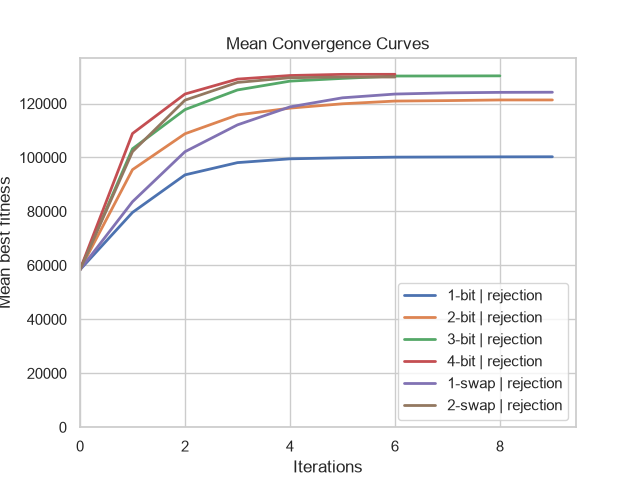

In [47]:
# The graphs
plot_convergance(analysis)